# 08 — Activity Classification with CNN + BiGRU

This notebook tests a second Deep Learning architecture for **6-class activity classification**.

The first IMU-only 1D CNN achieved:
- Test Accuracy: **88.36%**
- Balanced Accuracy: **88.70%**
- Macro F1: **0.8826**
- Weighted F1: **0.8842**

Its main weakness was confusion between **High Tempo Cycling** and **Low Tempo Cycling**.

This experiment adds a **Bidirectional GRU** after convolutional feature extraction to test whether longer temporal relationships improve activity recognition.

## Input
Only `ACC_X`, `ACC_Y`, `ACC_Z`

Input shape: `(N, 320, 3)`

The same exact 8-second windows and chronological train/validation/test split are reused.



## 1. Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Re-run the Final Preprocessing Pipeline

In [3]:
%%capture preprocessing_output
%run ./02_preprocessing_windowing.ipynb

## 3. Prepare IMU Inputs and Labels

In [4]:
X_acc_train = X_fusion_train[:, :, 1:4]
X_acc_val   = X_fusion_val[:, :, 1:4]
X_acc_test  = X_fusion_test[:, :, 1:4]

activity_to_id = {activity: idx for idx, activity in enumerate(ACTIVITY_ORDER)}
id_to_activity = {idx: activity for activity, idx in activity_to_id.items()}

y_activity_train = meta_train["Activity"].map(activity_to_id).to_numpy(dtype=np.int32)
y_activity_val   = meta_val["Activity"].map(activity_to_id).to_numpy(dtype=np.int32)
y_activity_test  = meta_test["Activity"].map(activity_to_id).to_numpy(dtype=np.int32)

print("Train:", X_acc_train.shape, y_activity_train.shape)
print("Val  :", X_acc_val.shape, y_activity_val.shape)
print("Test :", X_acc_test.shape, y_activity_test.shape)

assert X_acc_train.shape[1:] == (320, 3)

print()
print("Class mapping:")
for class_id, activity in id_to_activity.items():
    print(f"{class_id}: {activity}")

Train: (1322, 320, 3) (1322,)
Val  : (281, 320, 3) (281,)
Test : (292, 320, 3) (292,)

Class mapping:
0: Eating
1: High_Tempo_Cycling
2: Low_Tempo_Cycling
3: Sitting
4: Sleep
5: Walking


## 4. Training-Only Normalization

In [5]:
acc_mean = X_acc_train.mean(axis=(0, 1), keepdims=True)
acc_std = X_acc_train.std(axis=(0, 1), keepdims=True)

if np.any(acc_std == 0):
    raise ValueError("At least one accelerometer axis has zero standard deviation.")

X_acc_train_norm = (X_acc_train - acc_mean) / acc_std
X_acc_val_norm   = (X_acc_val - acc_mean) / acc_std
X_acc_test_norm  = (X_acc_test - acc_mean) / acc_std

normalization_table = pd.DataFrame({
    "Channel": ["ACC_X", "ACC_Y", "ACC_Z"],
    "Train_Mean": acc_mean.reshape(-1),
    "Train_Std": acc_std.reshape(-1),
    "Normalized_Train_Mean": X_acc_train_norm.mean(axis=(0, 1)),
    "Normalized_Train_Std": X_acc_train_norm.std(axis=(0, 1)),
})

display(normalization_table.round(5))

,Channel,Train_Mean,Train_Std,Normalized_Train_Mean,Normalized_Train_Std
0,ACC_X,-0.32539,0.55772,-0.00000,1.00000
1,ACC_Y,0.34338,0.23384,0.00004,0.99999
2,ACC_Z,-0.67551,0.31986,0.00006,0.99999


## 5. Class Weights

In [6]:
classes = np.arange(len(ACTIVITY_ORDER))

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_activity_train
)

class_weight = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

display(pd.DataFrame({
    "Class_ID": classes,
    "Activity": [id_to_activity[i] for i in classes],
    "Weight": weights,
}).round(3))

,Class_ID,Activity,Weight
0,0,Eating,6.677
1,1,High_Tempo_Cycling,1.288
2,2,Low_Tempo_Cycling,0.864
3,3,Sitting,1.154
4,4,Sleep,0.654
5,5,Walking,0.658


## 6. Reproducibility

In [7]:
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

## 7. Build CNN + BiGRU Activity Classifier

Architecture:

`ACC_X/Y/Z → Conv1D → BN → Pool → Conv1D → BN → Pool → BiGRU → Dense → 6-class Softmax`


In [8]:
def build_activity_cnn_bigru():
    inputs = tf.keras.layers.Input(shape=(320, 3), name="imu_input")

    x = tf.keras.layers.Conv1D(32, 7, padding="same", activation="relu")(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling1D(2)(x)

    x = tf.keras.layers.Conv1D(64, 5, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling1D(2)(x)

    x = tf.keras.layers.Bidirectional(
        tf.keras.layers.GRU(
            64,
            return_sequences=False,
            dropout=0.10
        ),
        name="activity_bigru"
    )(x)

    x = tf.keras.layers.Dropout(0.30)(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.20)(x)

    outputs = tf.keras.layers.Dense(
        len(ACTIVITY_ORDER),
        activation="softmax",
        name="activity_probabilities"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="IMU_CNN_BiGRU_Activity_Classifier"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

activity_bigru_model = build_activity_cnn_bigru()
activity_bigru_model.summary()

Model: "IMU_CNN_BiGRU_Activity_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imu_input (InputLayer)          │ (None, 320, 3)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 320, 32)        │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 320, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 160, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 160, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 80, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activity_bigru (Bidirectional)  │ (None, 128)            │        49,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activity_probabilities (Dense)  │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 69,958 (273.27 KB)

 Trainable params: 69,766 (272.52 KB)

 Non-trainable params: 192 (768.00 B)

## 8. Training Callbacks

In [9]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=6,
        min_lr=1e-6,
        verbose=1,
    ),
]

## 9. Train the CNN + BiGRU Classifier

In [ ]:
history = activity_bigru_model.fit(
    X_acc_train_norm,
    y_activity_train,
    validation_data=(X_acc_val_norm, y_activity_val),
    epochs=150,
    batch_size=32,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1,
)

## 10. Training History

Epochs trained: 20
Best epoch    : 5


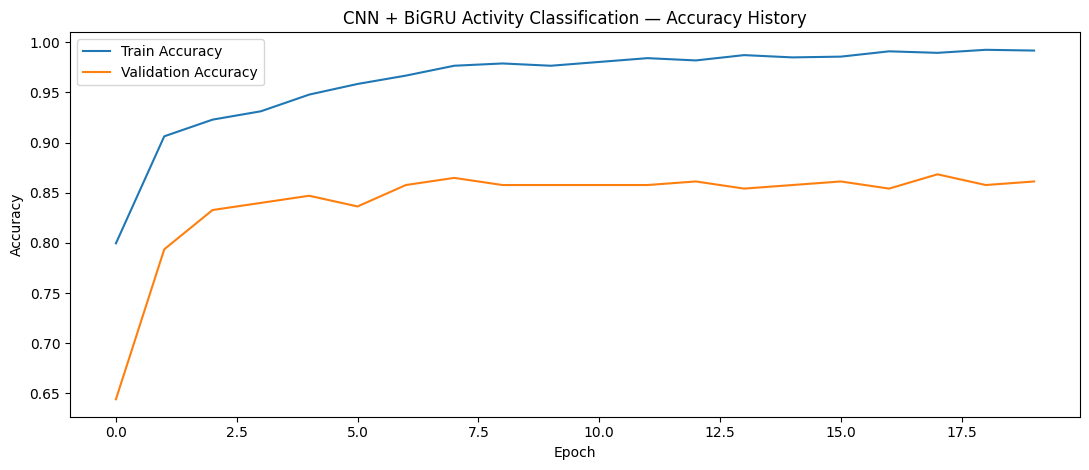

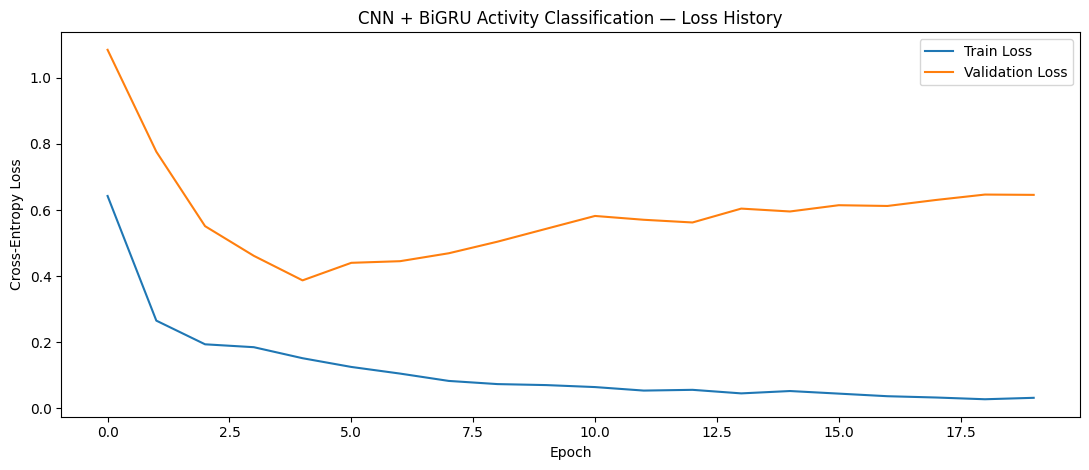

In [11]:
history_df = pd.DataFrame(history.history)

best_epoch = int(history_df["val_loss"].idxmin() + 1)
print("Epochs trained:", len(history_df))
print("Best epoch    :", best_epoch)

plt.figure(figsize=(11, 4.8))
plt.plot(history_df["accuracy"], label="Train Accuracy")
plt.plot(history_df["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN + BiGRU Activity Classification — Accuracy History")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 4.8))
plt.plot(history_df["loss"], label="Train Loss")
plt.plot(history_df["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("CNN + BiGRU Activity Classification — Loss History")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Test Predictions

In [12]:
test_probabilities = activity_bigru_model.predict(
    X_acc_test_norm,
    verbose=0
)

y_activity_pred = np.argmax(test_probabilities, axis=1)
print("Predictions:", y_activity_pred.shape)

Predictions: (292,)


## 12. Overall Classification Metrics

In [13]:
test_accuracy = accuracy_score(y_activity_test, y_activity_pred)
balanced_acc = balanced_accuracy_score(y_activity_test, y_activity_pred)
macro_f1 = f1_score(y_activity_test, y_activity_pred, average="macro")
weighted_f1 = f1_score(y_activity_test, y_activity_pred, average="weighted")

overall_metrics = pd.DataFrame([{
    "Model": "CNN + BiGRU",
    "Accuracy": test_accuracy,
    "Balanced_Accuracy": balanced_acc,
    "Macro_F1": macro_f1,
    "Weighted_F1": weighted_f1,
}])

display(overall_metrics.round(4))

print(f"Test Accuracy     : {test_accuracy * 100:.2f}%")
print(f"Balanced Accuracy : {balanced_acc * 100:.2f}%")
print(f"Macro F1          : {macro_f1:.4f}")
print(f"Weighted F1       : {weighted_f1:.4f}")

,Model,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1
0,CNN + BiGRU,0.8801,0.869,0.8637,0.8763


Test Accuracy     : 88.01%
Balanced Accuracy : 86.90%
Macro F1          : 0.8637
Weighted F1       : 0.8763


## 13. Compare with the Previous 1D CNN

In [14]:
classifier_comparison = pd.DataFrame([
    {
        "Model": "1D CNN",
        "Accuracy": 0.8836,
        "Balanced_Accuracy": 0.8870,
        "Macro_F1": 0.8826,
        "Weighted_F1": 0.8842,
    },
    {
        "Model": "CNN + BiGRU",
        "Accuracy": test_accuracy,
        "Balanced_Accuracy": balanced_acc,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1,
    }
])

display(classifier_comparison.round(4))

print("Accuracy change:", f"{(test_accuracy - 0.8836) * 100:+.2f} percentage points")
print("Macro F1 change:", f"{macro_f1 - 0.8826:+.4f}")

,Model,Accuracy,Balanced_Accuracy,Macro_F1,Weighted_F1
0,1D CNN,0.8836,0.887,0.8826,0.8842
1,CNN + BiGRU,0.8801,0.869,0.8637,0.8763


Accuracy change: -0.35 percentage points
Macro F1 change: -0.0189


## 14. Per-Class Precision, Recall and F1

In [15]:
report = classification_report(
    y_activity_test,
    y_activity_pred,
    labels=classes,
    target_names=[a.replace("_", " ") for a in ACTIVITY_ORDER],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
display(report_df.round(3))

,precision,recall,f1-score,support
Eating,0.889,1.000,0.941,8.00
High Tempo Cycling,0.700,0.553,0.618,38.00
Low Tempo Cycling,0.729,0.768,0.748,56.00
Sitting,0.951,0.907,0.929,43.00
Sleep,0.961,1.000,0.980,73.00
Walking,0.948,0.986,0.967,74.00
accuracy,0.880,0.880,0.880,0.88
macro avg,0.863,0.869,0.864,292.00
weighted avg,0.876,0.880,0.876,292.00


## 15. Confusion Matrix

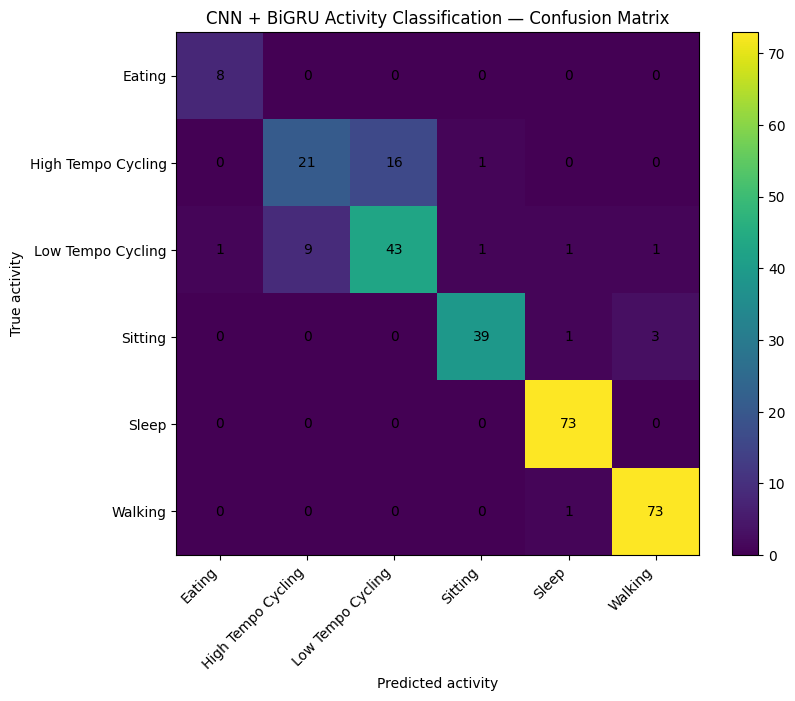

In [16]:
cm = confusion_matrix(
    y_activity_test,
    y_activity_pred,
    labels=classes
)

tick_labels = [a.replace("_", " ") for a in ACTIVITY_ORDER]

plt.figure(figsize=(8.5, 7))
plt.imshow(cm)
plt.colorbar()

plt.xticks(np.arange(len(classes)), tick_labels, rotation=45, ha="right")
plt.yticks(np.arange(len(classes)), tick_labels)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.xlabel("Predicted activity")
plt.ylabel("True activity")
plt.title("CNN + BiGRU Activity Classification — Confusion Matrix")
plt.tight_layout()
plt.show()

## 16. Normalized Confusion Matrix

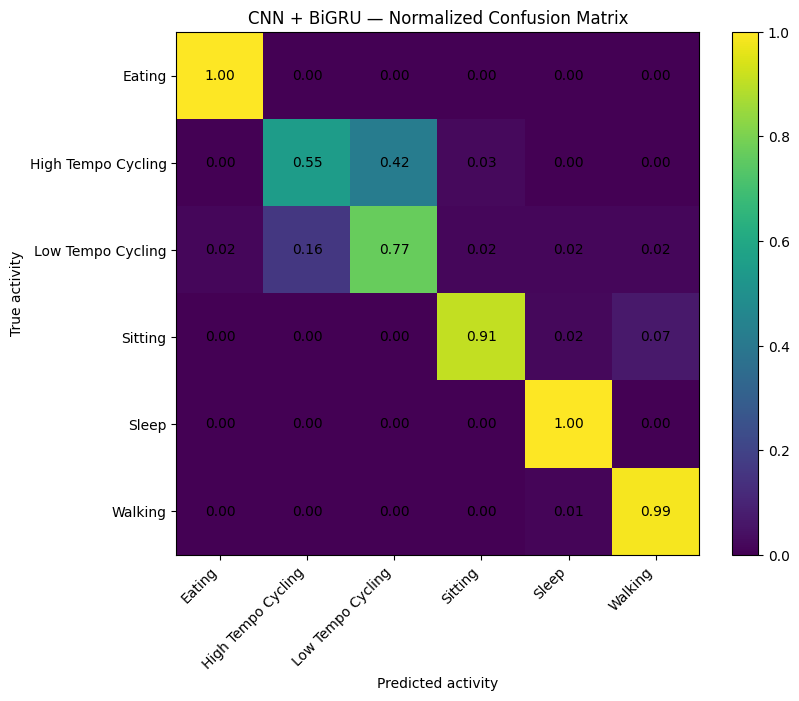

In [17]:
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8.5, 7))
plt.imshow(cm_normalized, vmin=0, vmax=1)
plt.colorbar()

plt.xticks(np.arange(len(classes)), tick_labels, rotation=45, ha="right")
plt.yticks(np.arange(len(classes)), tick_labels)

for i in range(cm_normalized.shape[0]):
    for j in range(cm_normalized.shape[1]):
        plt.text(j, i, f"{cm_normalized[i, j]:.2f}", ha="center", va="center")

plt.xlabel("Predicted activity")
plt.ylabel("True activity")
plt.title("CNN + BiGRU — Normalized Confusion Matrix")
plt.tight_layout()
plt.show()

## 17. Per-Activity Accuracy

,Activity,Test_Windows,Correct,Accuracy
0,Eating,8,8,1.000
1,High_Tempo_Cycling,38,21,0.553
2,Low_Tempo_Cycling,56,43,0.768
3,Sitting,43,39,0.907
4,Sleep,73,73,1.000
5,Walking,74,73,0.986


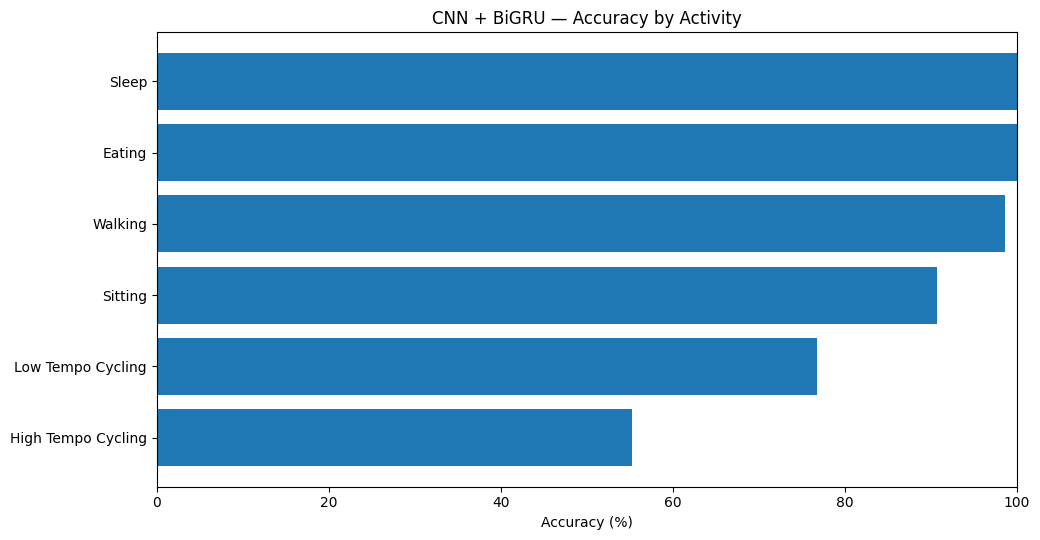

In [18]:
per_activity_rows = []

for class_id, activity in id_to_activity.items():
    mask = y_activity_test == class_id
    if not np.any(mask):
        continue

    correct = y_activity_pred[mask] == y_activity_test[mask]

    per_activity_rows.append({
        "Activity": activity,
        "Test_Windows": int(mask.sum()),
        "Correct": int(correct.sum()),
        "Accuracy": float(correct.mean()),
    })

per_activity_accuracy = pd.DataFrame(per_activity_rows)
display(per_activity_accuracy.round(3))

plot_df = per_activity_accuracy.sort_values("Accuracy")

plt.figure(figsize=(10.5, 5.5))
plt.barh(
    plot_df["Activity"].str.replace("_", " "),
    plot_df["Accuracy"] * 100
)
plt.xlabel("Accuracy (%)")
plt.title("CNN + BiGRU — Accuracy by Activity")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

## 18. High vs Low Tempo Cycling Diagnostic

The first classifier mainly confused High Tempo Cycling with Low Tempo Cycling.
This table isolates those two classes.


In [19]:
cycling_rows = []

for activity in ["High_Tempo_Cycling", "Low_Tempo_Cycling"]:
    class_id = activity_to_id[activity]
    mask = y_activity_test == class_id

    recall = float(np.mean(y_activity_pred[mask] == class_id))

    cycling_rows.append({
        "Activity": activity,
        "Test_Windows": int(mask.sum()),
        "Correct": int(np.sum(y_activity_pred[mask] == class_id)),
        "Recall": recall,
    })

cycling_diagnostic = pd.DataFrame(cycling_rows)
display(cycling_diagnostic.round(3))

print()
print("Previous 1D CNN:")
print("High Tempo Cycling recall: 78.9%")
print("Low Tempo Cycling recall : 64.3%")

,Activity,Test_Windows,Correct,Recall
0,High_Tempo_Cycling,38,21,0.553
1,Low_Tempo_Cycling,56,43,0.768



Previous 1D CNN:
High Tempo Cycling recall: 78.9%
Low Tempo Cycling recall : 64.3%


## 19. Prediction Confidence

In [20]:
prediction_confidence = np.max(test_probabilities, axis=1)
correct_mask = y_activity_pred == y_activity_test

confidence_summary = pd.DataFrame({
    "Group": [
        "All test windows",
        "Correct predictions",
        "Incorrect predictions",
    ],
    "Mean_Confidence": [
        prediction_confidence.mean(),
        prediction_confidence[correct_mask].mean() if np.any(correct_mask) else np.nan,
        prediction_confidence[~correct_mask].mean() if np.any(~correct_mask) else np.nan,
    ],
})

display(confidence_summary.round(3))

,Group,Mean_Confidence
0,All test windows,0.864
1,Correct predictions,0.898
2,Incorrect predictions,0.616


## 20. Conclusion

The CNN + BiGRU classifier achieved 88.01% test accuracy,
86.90% balanced accuracy, and a Macro F1 score of 0.8637.

Although the model improved Low Tempo Cycling recall,
it performed worse on High Tempo Cycling compared with
the simpler 1D CNN.

The CNN + BiGRU classifier did not outperform the 1D CNN
in overall accuracy, balanced accuracy, or Macro F1.

Therefore, the IMU-only 1D CNN was retained as the final
activity classifier.